# DA-012 — Public Transport Ridership Analysis

**Case study:** UC Merced CatTracks campus bus system  
**Routes:** C1 Blue, C1 Gold, C2 Express and G-Line  
**Billing periods:** October 2018 and February 2019

## Project aim

This notebook analyses recorded passenger boardings from the source workbooks. It extracts the aggregate **PAX ON** tables, cleans the data, summarises passenger demand by route and stop, studies scheduled departure-time patterns, and compares predefined peak and off-peak periods.

> This is a descriptive analysis of historical aggregate data. It is not a live transit dashboard or a passenger-level forecasting model.

**Upstream source:** [UCM CatTracks Simulator](https://github.com/nlt-python/UCM_CatTracks_Simulator). See the repository's `NOTICE.md` for attribution and adaptation details.

## 1. Import libraries and locate project files

Install packages first with `pip install -r requirements.txt` from the project root.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.ridership_analysis import (
    load_ridership_data,
    build_summary_tables,
    quality_report,
    save_analysis_outputs,
)

DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
print("Project root:", PROJECT_ROOT)
print("Data directory exists:", DATA_DIR.exists())

Project root: /Users/jynxenq/Downloads/DA-012-Public-Transport-Analytics
Data directory exists: True


## 2. Load and extract the aggregate boarding data

Each route worksheet contains multiple weekday blocks and an aggregate table. The extraction helper locates the right-most aggregate **PAX ON** table rather than relying on manually selected column numbers.

In [2]:
ridership = load_ridership_data(DATA_DIR)
print(f"Rows in tidy dataset: {len(ridership):,}")
display(ridership.head(10))

Rows in tidy dataset: 1,114


,period,route,stop,departure_time,source_workbook,passenger_count,departure_minutes,departure_hour,time_band,peak_status,period_order
0,February 2019,C1 Blue,Alexander & G Street,05:45,219-CATTRACKS Fall 2019- February Billing.xlsx,2.0,345,5,Early morning,Off-peak,2
1,February 2019,C1 Blue,Arrow Wood Drive,05:45,219-CATTRACKS Fall 2019- February Billing.xlsx,11.0,345,5,Early morning,Off-peak,2
2,February 2019,C1 Blue,Mercy Hospital,05:45,219-CATTRACKS Fall 2019- February Billing.xlsx,3.0,345,5,Early morning,Off-peak,2
3,February 2019,C1 Blue,Muir Pass,05:45,219-CATTRACKS Fall 2019- February Billing.xlsx,5.0,345,5,Early morning,Off-peak,2
4,February 2019,C1 Blue,Rite Aid/Walgreen,05:45,219-CATTRACKS Fall 2019- February Billing.xlsx,2.0,345,5,Early morning,Off-peak,2
5,February 2019,C1 Blue,Scholars/Emigrant,05:45,219-CATTRACKS Fall 2019- February Billing.xlsx,1.0,345,5,Early morning,Off-peak,2
6,February 2019,C1 Blue,Alexander & G Street,07:04,219-CATTRACKS Fall 2019- February Billing.xlsx,24.0,424,7,Morning peak,Peak,2
7,February 2019,C1 Blue,Arrow Wood Drive,07:04,219-CATTRACKS Fall 2019- February Billing.xlsx,194.0,424,7,Morning peak,Peak,2
8,February 2019,C1 Blue,El Portal Plaza,07:04,219-CATTRACKS Fall 2019- February Billing.xlsx,21.0,424,7,Morning peak,Peak,2
9,February 2019,C1 Blue,El Portal Plaza / G Street,07:04,219-CATTRACKS Fall 2019- February Billing.xlsx,1.0,424,7,Morning peak,Peak,2


## 3. Data quality checks

The tidy table includes only numeric, non-negative, positive boarding counts. Missing or zero counts are not plotted as observations. The checks below provide a compact validation summary.

In [3]:
display(quality_report(ridership))
print("Missing values by field:")
display(ridership.isna().sum().to_frame("missing_values"))

,check,result
0,Rows after extraction,1114
1,Missing values across columns,0
2,Negative passenger counts,0
3,Unique routes,4
4,Unique stop names,25
5,Unique scheduled departure times,65


Missing values by field:


,missing_values
period,0
route,0
stop,0
departure_time,0
source_workbook,0
passenger_count,0
departure_minutes,0
departure_hour,0
time_band,0
peak_status,0


## 4. Route-level ridership analysis

Compare total recorded boardings by route across the two billing periods. These are billing-period totals and are not adjusted for operating-day counts.

In [4]:
summaries = build_summary_tables(ridership)
route_summary = summaries["route_summary"]
display(route_summary.pivot(index="route", columns="period", values="total_boardings").fillna(0))

period,February 2019,October 2018
route,,
C1 Blue,4304.0,5976.0
C1 Gold,4005.0,5829.0
C2 Express,12053.0,13552.0
G-Line,6299.0,5261.0


## 5. Stop-level ridership analysis

Identify stops with the largest total recorded boarding counts across both source periods. Stop labels are retained from the source; repeated names within a route are combined during data preparation.

In [5]:
top_stops = (
    summaries["stop_summary"].groupby("stop", as_index=False)["total_boardings"]
    .sum().sort_values("total_boardings", ascending=False).head(10)
)
display(top_stops)

,stop,total_boardings
17,Muir Pass,21233.0
3,Arrow Wood Drive,8453.0
15,Merced Mall Target,3866.0
19,Scholars/Emigrant,3529.0
9,El Redondo,2885.0
6,Compass Pointe,2214.0
22,"Village Apts ""R"" Street",1725.0
10,Granville Apts,1674.0
23,"Villages Apts ""M""",1556.0
18,Rite Aid/Walgreen,1440.0


## 6. Peak and off-peak analysis

For this project, peak windows are defined as **07:00–09:59** and **16:00–18:59**. Other scheduled departure times are classified as off-peak. These are analytical assumptions, not official definitions supplied by the transit operator.

In [6]:
peak_table = summaries["peak_offpeak_summary"]
display(peak_table.pivot_table(
    index=["period", "route"], columns="peak_status",
    values="total_boardings", fill_value=0
))

peak_status               Off-peak    Peak
period        route                       
February 2019 C1 Blue       2503.0  1801.0
              C1 Gold       2230.0  1775.0
              C2 Express    6274.0  5779.0
              G-Line        3612.0  2687.0
October 2018  C1 Blue       3409.0  2567.0
              C1 Gold       3288.0  2541.0
              C2 Express    7335.0  6217.0
              G-Line        2716.0  2545.0

## 7. Generate charts and export tables

The following cell saves five figures and six CSV tables under `outputs/`. The charts can also be viewed directly in the repository's `outputs/charts/` folder.

Saved 11 files
01_route_ridership_comparison.png


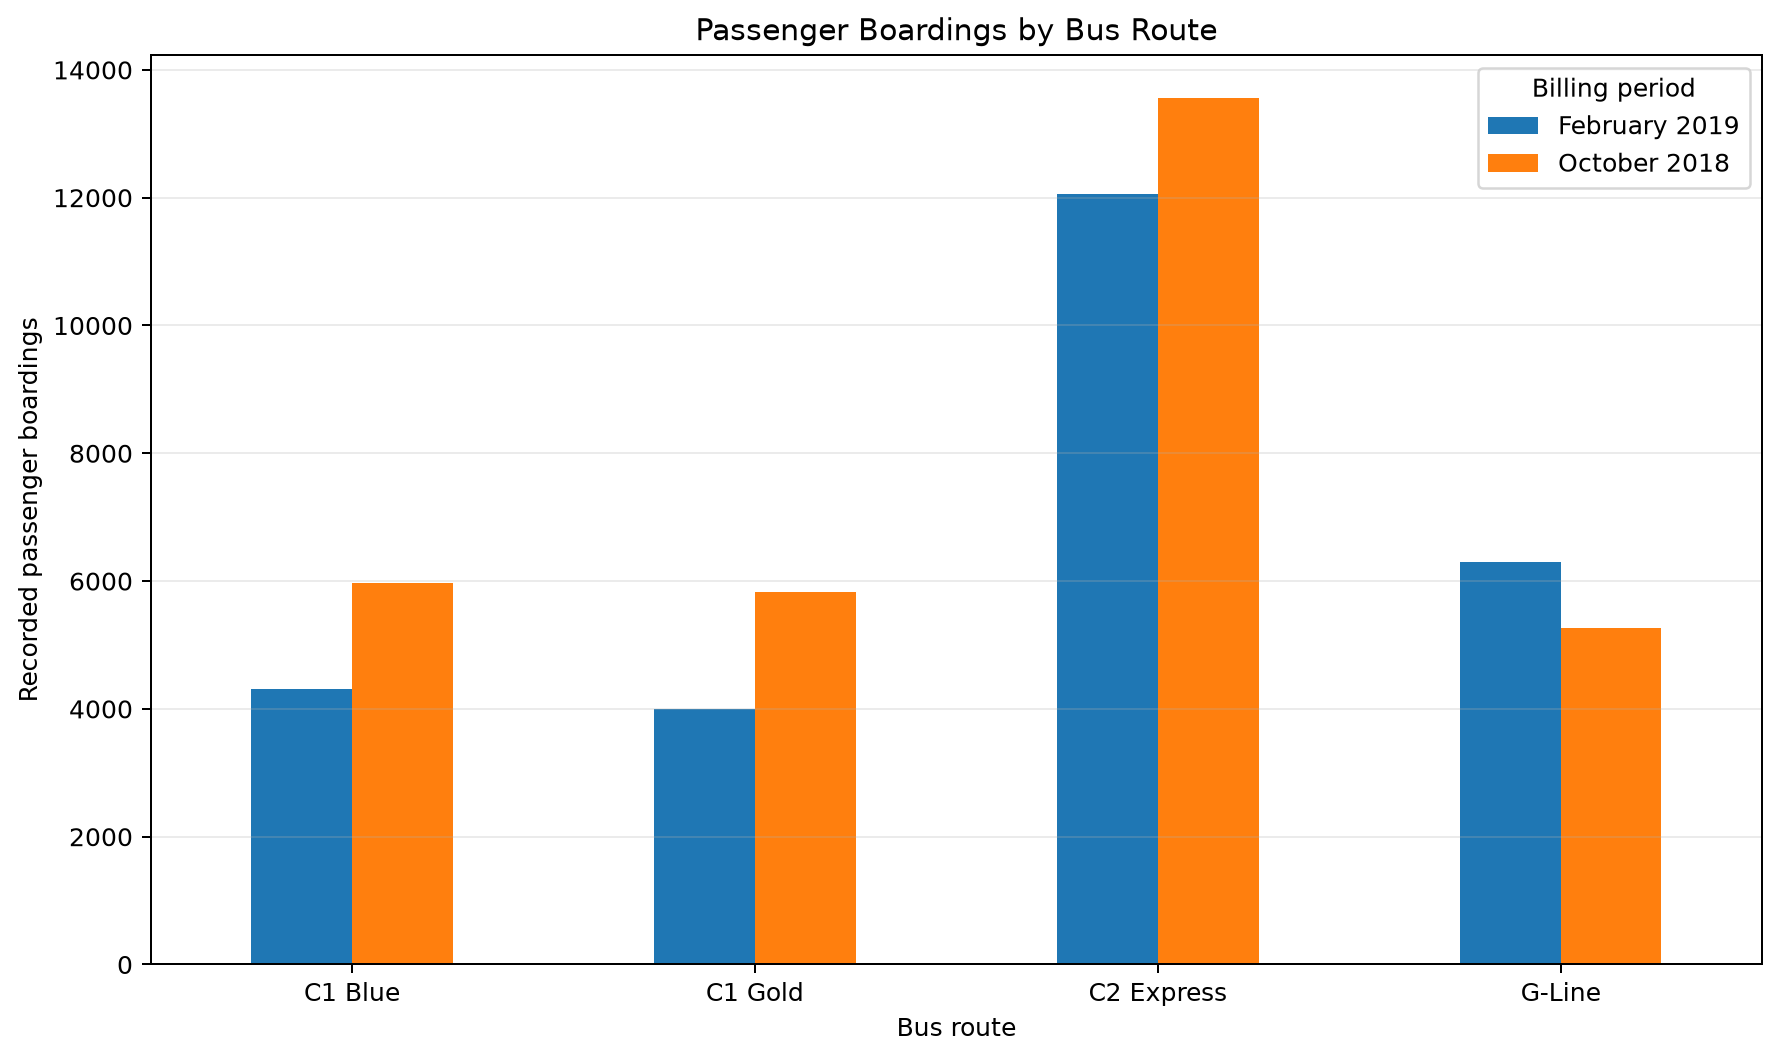

02_top_10_stops.png


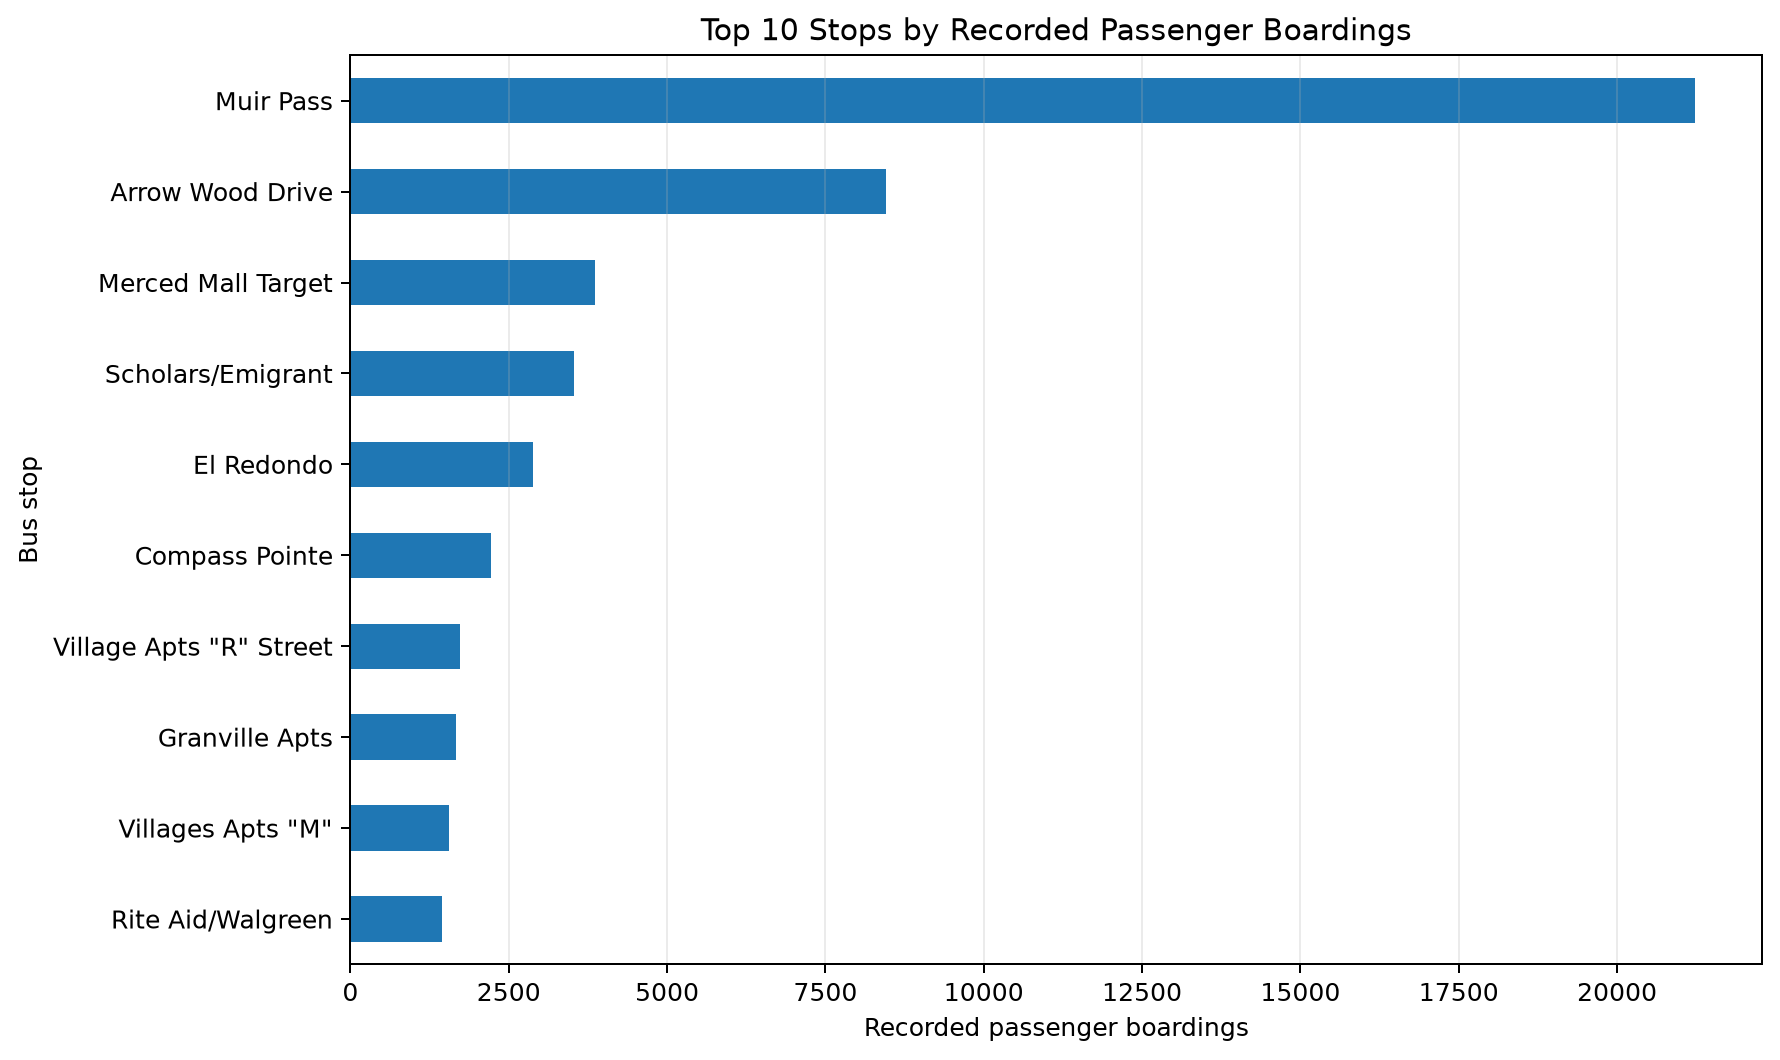

03_demand_by_departure_time.png


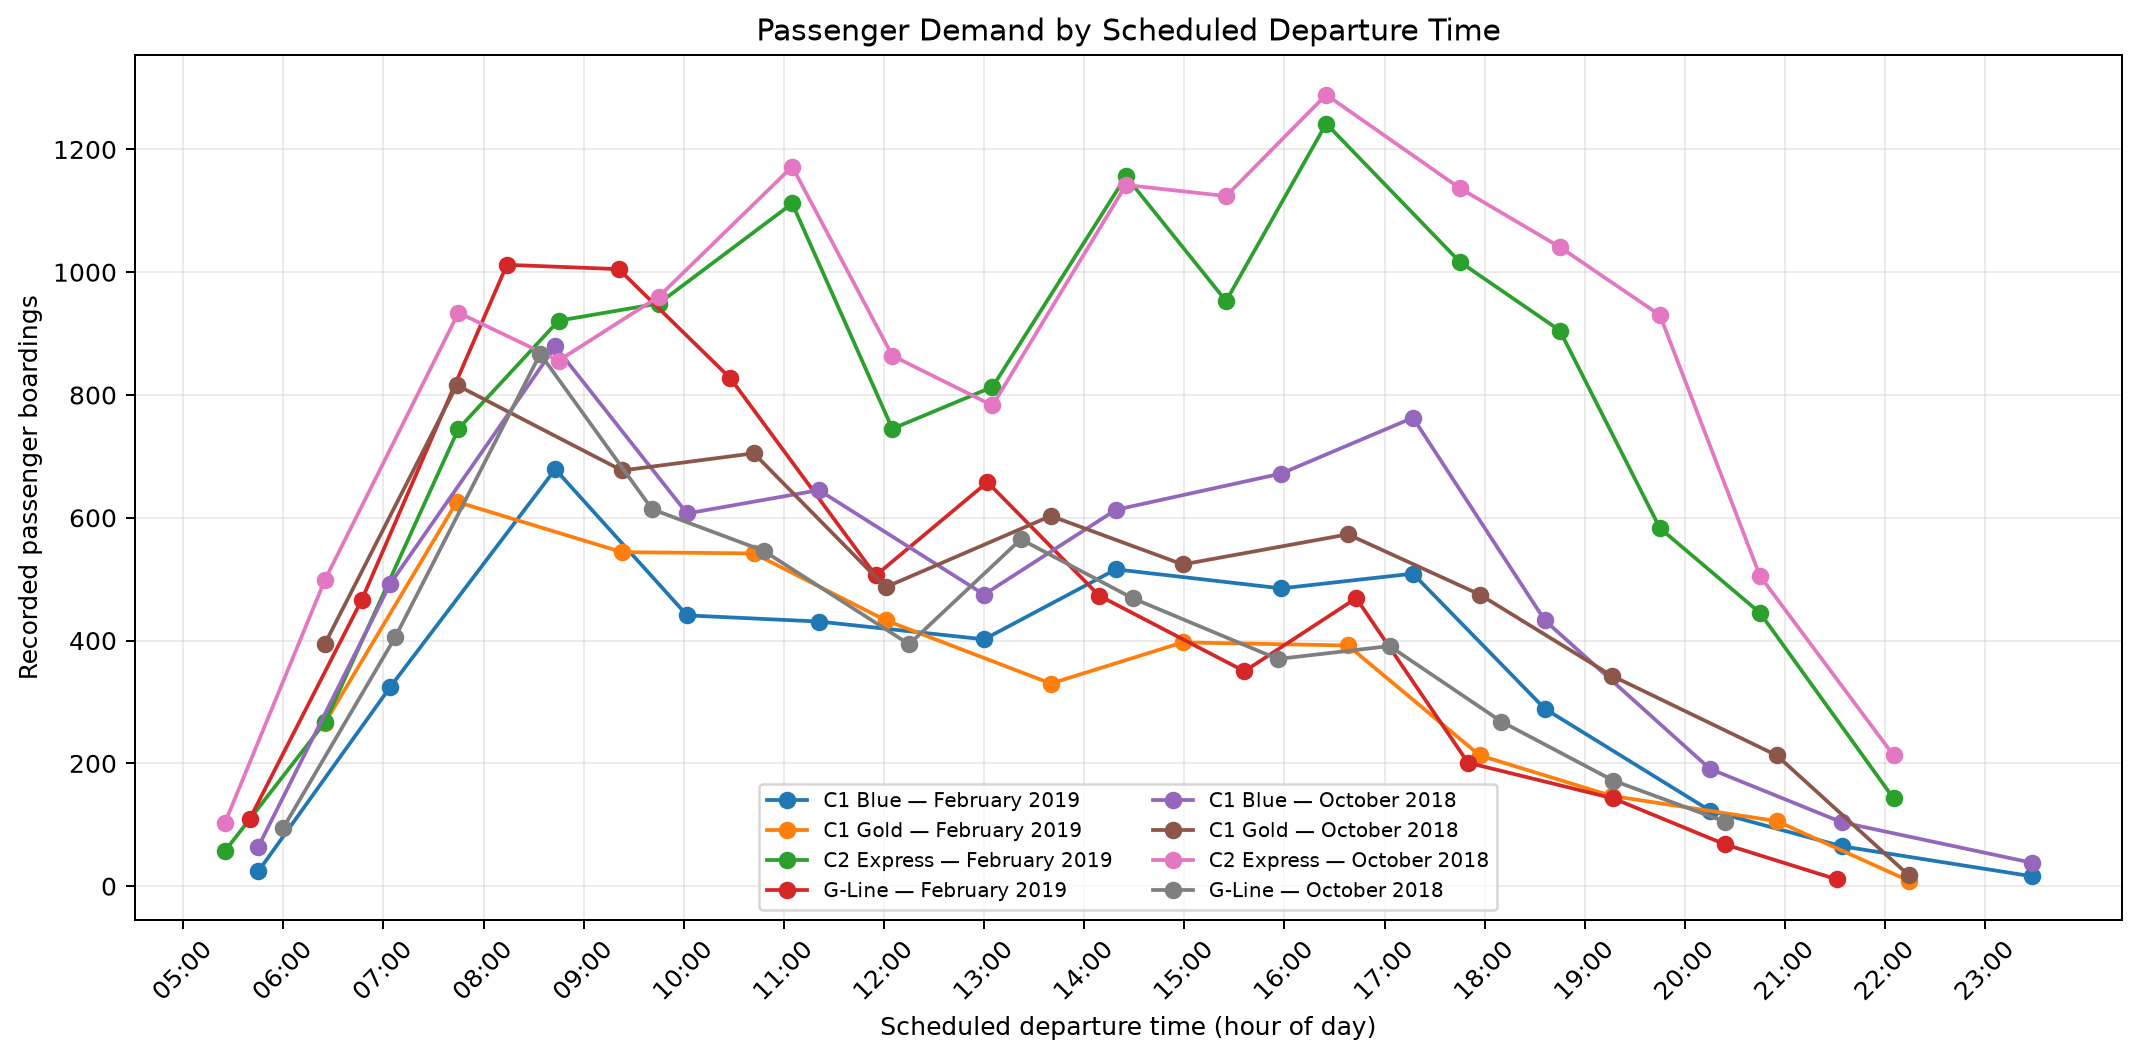

04_peak_vs_offpeak.png


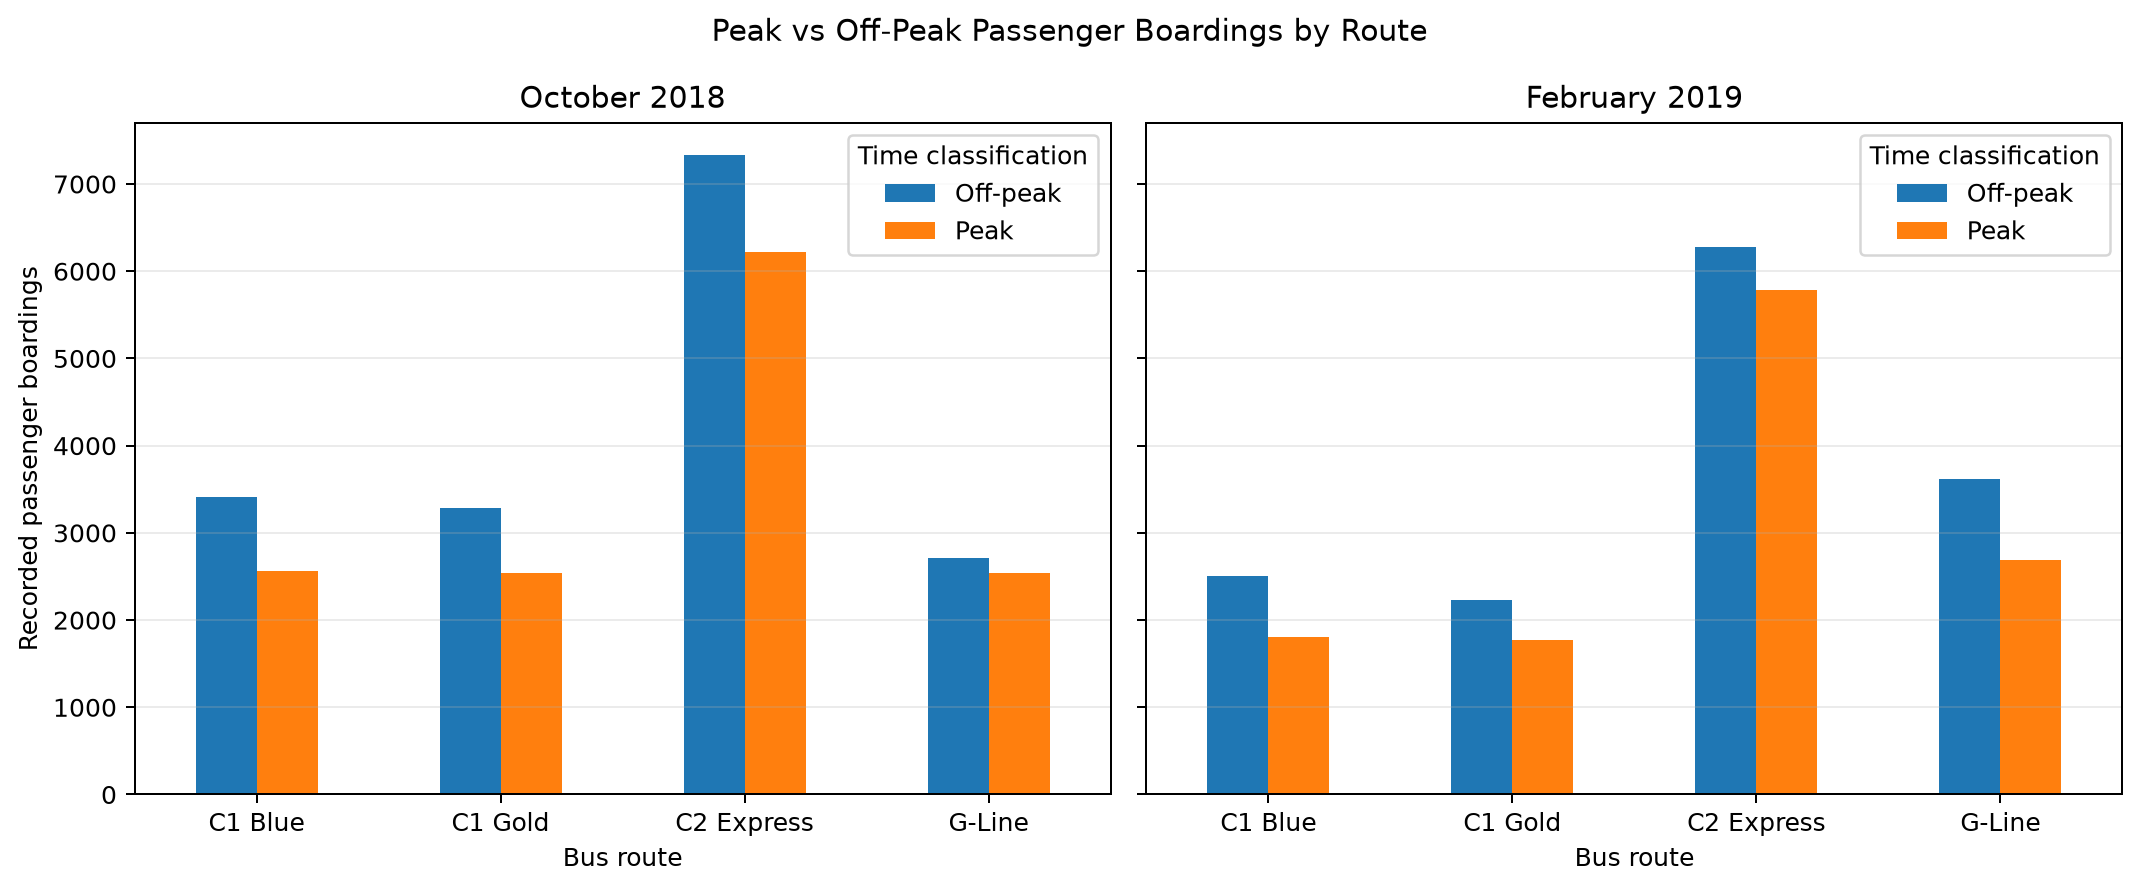

05_route_share.png


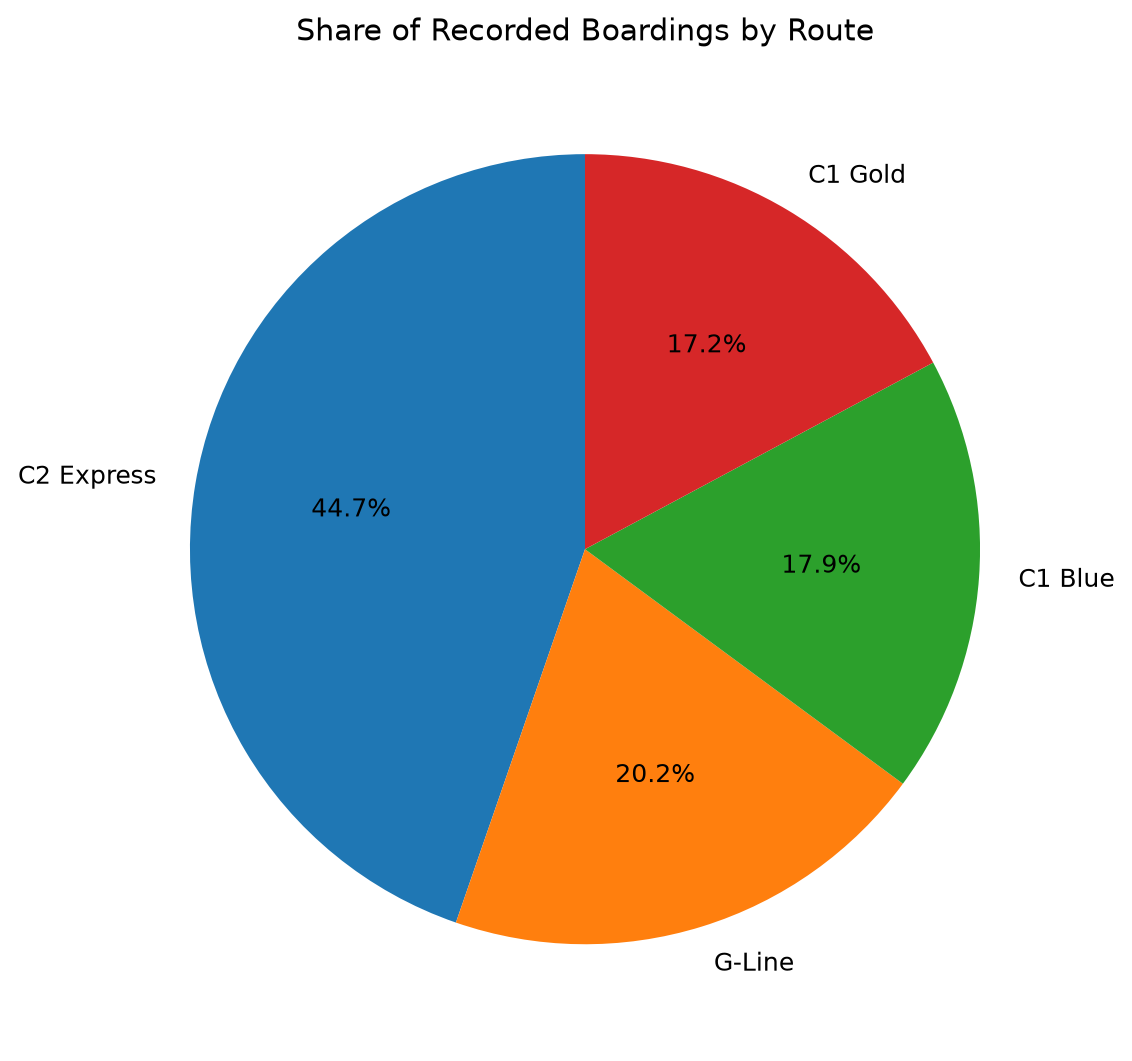

In [7]:
saved_outputs = save_analysis_outputs(ridership, summaries, OUTPUT_DIR)
print(f"Saved {len(saved_outputs)} files")
for chart_path in sorted((OUTPUT_DIR / "charts").glob("*.png")):
    print(chart_path.name)
    display(Image(filename=str(chart_path)))

## 8. Interpretation and limitations

Use the tables and charts to describe differences in the supplied records. Do not infer causation or claim that one period represents growth/decline without adjusting for the number of service days and checking schedule changes.

Key limitations:

- Only four weekday routes are analysed.
- The input data are historical billing-period aggregates, not individual passenger records.
- Passenger boardings do not represent unique people.
- The aggregate tables do not support a reliable daily or weekend comparison in this project.
- Peak-hour windows are predefined assumptions.

## 9. Conclusion

The analysis demonstrates a reproducible data analytics workflow: workbook inspection, structured extraction, data cleaning, feature engineering, aggregation, visualisation, and interpretation. Recommendations should be based on the observed route, stop, and scheduled-departure patterns, while acknowledging the limits of the available data.